In [17]:
import hashlib
import os
import platform
import uuid


STUDENT_ID = 2024080204  

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp01
[学号] 2024080204
[机器指纹] 00582d46724e0b27
[RUN_ID] 2024080204-00582d46724e0b27


任务 1：围绕半圆定律 (Semicircle Law)

In [18]:
import numpy as np
import matplotlib.pyplot as plt

1.1 编写 wigner_density(x)

In [19]:
def wigner_density(x):
    if abs(x) <= 2:
        return float(np.sqrt(4 - x**2) / (2 * np.pi))
    else:
        return 0.0

1.2 编写 generate_wigner(n)
利用 np.random.normal 生成正态分布，用 np.triu 提取上三角，再组合成对称矩阵。

In [20]:
def generate_wigner(n):
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n 必须是正整数")
    
    # 生成上三角矩阵（均值为0，方差为1/n，即标准差为1/sqrt(n)）
    A = np.random.normal(0, 1 / np.sqrt(n), size=(n, n))
    upper = np.triu(A)
    
    # 镜像并填充对角线，构造对称矩阵
    Z = upper + upper.T - np.diag(np.diag(upper))
    return Z

1.3 编写 get_spectrum(matrix)
对于对称矩阵，使用 np.linalg.eigvalsh 比 eigvals 更快更稳定，且它自带排序功能，但为了严格符合题目要求，我们显式调用 np.sort。

In [21]:
def get_spectrum(matrix):
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)

1.4 绘制四个子图

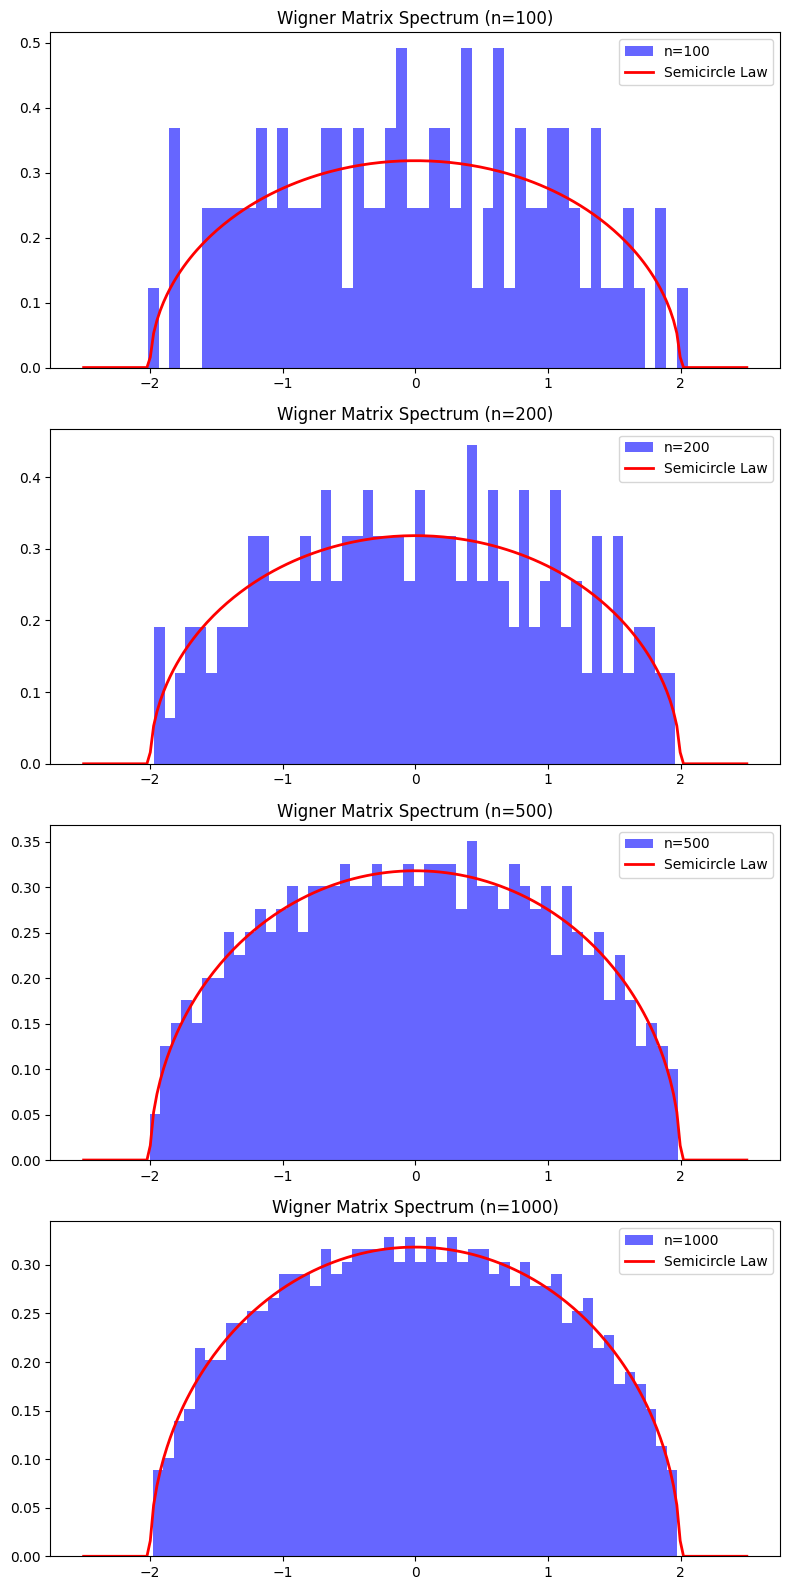

In [22]:
fig, axes = plt.subplots(4, 1, figsize=(8, 16))
n_values = [100, 200, 500, 1000]

for ax, n in zip(axes, n_values):
    # 生成矩阵并获取特征值
    W = generate_wigner(n)
    eigvals = get_spectrum(W)
    
    # 画标准化直方图
    ax.hist(eigvals, bins=50, density=True, color='blue', alpha=0.6, label=f'n={n}')
    
    # 叠加红色的半圆密度曲线
    x = np.linspace(-2.5, 2.5, 200)
    y = np.array([wigner_density(val) for val in x])
    ax.plot(x, y, color='red', linewidth=2, label='Semicircle Law')
    
    ax.set_title(f'Wigner Matrix Spectrum (n={n})')
    ax.legend()

plt.tight_layout()
plt.show()

图形分析结论：
随着矩阵阶数 n 的增大，特征值的标准化直方图越来越平滑，且边缘收敛得更好。大约在 n=500或 n=1000 时，直方图的轮廓能较好地贴合红色的半圆密度曲线。这验证了随机矩阵理论中的 Wigner 半圆定律。

任务 2：Conway 的生命游戏 (Game of Life)
2.1 编写 is_valid_board(board)

In [23]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    # 判断元素是否全为 0 或 1
    if not np.all(np.isin(board, [0, 1])):
        return False
    return True

2.2 编写 gol_step(board)
这里有一个非常巧妙的技巧：利用 np.roll 实现环绕边界的邻居计数。

In [24]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("无效的棋盘输入")
        
    # 利用 np.roll 将矩阵上下左右及对角平移，然后相加得到每个格子的邻居数
    neighbors = sum(
        np.roll(np.roll(board, i, axis=0), j, axis=1)
        for i in (-1, 0, 1) for j in (-1, 0, 1)
        if (i, j) != (0, 0) # 排除自己
    )
    
    # 规则实现：
    # 1. 活细胞 (board == 1) 有 2 或 3 个邻居时存活
    # 2. 死细胞 (board == 0) 有恰好 3 个邻居时复活
    next_board = ((board == 1) & ((neighbors == 2) | (neighbors == 3))) | \
                 ((board == 0) & (neighbors == 3))
                 
    return next_board.astype(int)

2.3 编写 draw_gol_board(board)

In [25]:
def draw_gol_board(board):
    # cmap='gray_r' 表示翻转的灰度图（0变白，1变黑）
    plt.imshow(board, cmap='gray_r')
    # 关闭坐标轴刻度和标签
    plt.xticks([])
    plt.yticks([])
    # 关闭轴线
    plt.axis('off')
    plt.show()

2.4 测试

=== 测试棋盘合法性 ===
合法棋盘 (应为True): True
非法棋盘 (应为False): False

=== 测试 gol_step 演化 ===
原棋盘：
[[0 1 0 0 0]
 [0 0 1 0 0]
 [1 1 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]

下一步的棋盘：
[[0 0 0 0 0]
 [1 0 1 0 0]
 [0 1 1 0 0]
 [0 1 0 0 0]
 [0 0 0 0 0]]

=== 测试 draw_gol_board 画图 ===


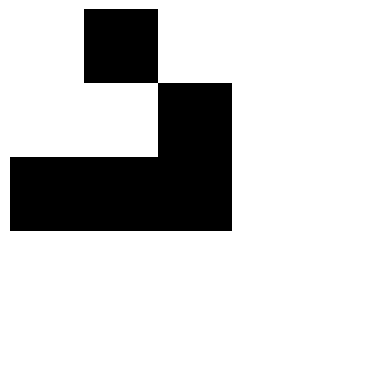

In [26]:
# ================= 测试任务二 =================

# 1. 测试 is_valid_board
print("=== 测试棋盘合法性 ===")
board_valid = np.array([[0, 1], [1, 0]])
board_invalid = np.array([[0, 2], [1, 0]])
print("合法棋盘 (应为True):", is_valid_board(board_valid))
print("非法棋盘 (应为False):", is_valid_board(board_invalid))

# 2. 创建一个经典的生命游戏图案（滑翔机 Glider）
print("\n=== 测试 gol_step 演化 ===")
board = np.zeros((5, 5), dtype=int)
board[0, 1] = 1
board[1, 2] = 1
board[2, 0] = 1
board[2, 1] = 1
board[2, 2] = 1

print("原棋盘：")
print(board)

next_board = gol_step(board)
print("\n下一步的棋盘：")
print(next_board)

# 3. 测试画图函数
print("\n=== 测试 draw_gol_board 画图 ===")
draw_gol_board(board)

关于生命游戏：

is_valid_board 通过 np.isin 检查是否只有 0 和 1，确保棋盘元素合法。

gol_step 巧妙利用了 np.roll 将矩阵沿上下左右及四个对角方向进行平移并相加，一步到位地算出了所有细胞周围 8 个方向的存活邻居数，并且完美契合了题目要求的“环绕边界”条件。

draw_gol_board 使用 imshow 和灰度翻转（gray_r）实现黑白块可视化。

任务 3：使用 pandas DataFrame

In [27]:
import pandas as pd
import numpy as np

3.1 读取并回答问题

In [28]:
# 1. 读取数据
df = pd.read_csv('iris.csv')

# 因为你的 CSV 第一列没有名字（默认是索引），为了整洁，把第一列丢掉
if 'Unnamed: 0' in df.columns:
    df = df.drop('Unnamed: 0', axis=1)

# 补上缺失的 Species 列
df['Species'] = ['setosa'] * 50 + ['versicolor'] * 50 + ['virginica'] * 50

print("=== 任务1 ===")
print(f"数据集包含 {df.shape[0]} 个数据点。")
print("每列的数据类型：\n", df.dtypes)
print("列名是：", df.columns.tolist())
print("数据中有", df['Species'].nunique(), "种花卉：", df['Species'].unique())

=== 任务1 ===
数据集包含 150 个数据点。
每列的数据类型：
 sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
Species               object
dtype: object
列名是： ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'Species']
数据中有 3 种花卉： ['setosa' 'versicolor' 'virginica']


数据集有 150 个数据点。数据类型大部分是浮点数（float64），Species 是字符串（object）。列名分别是 Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species。

3.2 修改错误数据行

In [29]:
# 2. 修改错误的数据行 (原文件中索引34和37的行)
print("\n=== 任务2 ===")
# 你的文件里，35行和38行其实正好是索引34和37
df.loc[34, ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'Species']] = [4.9, 3.1, 1.5, 0.2, 'setosa']
df.loc[37, ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'Species']] = [4.9, 3.6, 1.4, 0.1, 'setosa']

print("修改后的第34和37行：")
print(df.loc[[34, 37]])


=== 任务2 ===
修改后的第34和37行：
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
34                4.9               3.1                1.5               0.2   
37                4.9               3.6                1.4               0.1   

   Species  
34  setosa  
37  setosa  


3.3  添加新特征

In [30]:
print("\n=== 任务3 ===")
df['Petal.Ratio'] = df['petal length (cm)'] / df['petal width (cm)']
df['Sepal.Ratio'] = df['sepal length (cm)'] / df['sepal width (cm)']
print(df[['Petal.Ratio', 'Sepal.Ratio']].head())


=== 任务3 ===
   Petal.Ratio  Sepal.Ratio
0          7.0     1.457143
1          7.0     1.633333
2          6.5     1.468750
3          7.5     1.483871
4          7.0     1.388889


3.4 保存

In [31]:
df.to_csv('iris_corrected.csv', index=False)
print("\n文件已保存为 iris_corrected.csv")


文件已保存为 iris_corrected.csv


3.5 分组统计

In [32]:
print("\n=== 任务5 ===")
agg_funcs = ['mean', 'median', 'min', 'max', 'std']
summary = df.groupby('Species')[['Petal.Ratio', 'Sepal.Ratio']].agg(agg_funcs)
print(summary)


=== 任务5 ===
           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
Species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.471380   
versicolor    3.182408  3.230769  0.335714   4.1  0.515861    2.165531   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
Species                                             
setosa      1.466667  1.268293  1.956522  0.119677  
versicolor  2.161290  1.764706  2.818182  0.228104  
virginica   2.169540  1.823529  2.961538  0.246992  
